# 04 — Estudo de ablação: decomposição por média móvel e filtragem por FFT

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

O enunciado (item 2.2) pede pelo menos duas técnicas de pré-processamento, comparando o desempenho **com e sem** cada uma. Escolhemos as duas que a análise exploratória (notebook 01, seção 5) indicou para o nosso sinal:

| Técnica | Categoria do enunciado | O que faz com a série | Hipótese |
|---|---|---|---|
| **MM**: decomposição por média móvel | decomposição (estilo Autoformer/DLinear) | separa cada canal em **tendência** (média móvel centrada de $k$ instantes) e **resíduo** (sinal − tendência) e entrega os dois como canais separados | o modelo passa a ver o movimento real separado do tremor do MediaPipe e pode dar pesos diferentes a cada um |
| **FFT**: filtro passa-baixa | domínio da frequência | transforma cada canal com a FFT, zera as frequências acima de $K$ ciclos por sinal e volta ao tempo | remove o tremor e os "degraus" das falhas de detecção, que estão nas altas frequências |
| **Ambas** | — | filtra com a FFT e depois decompõe o sinal filtrado | os efeitos se somam? |

As quatro versões dos dados (bruto, MM, FFT e ambas) passam **pelos mesmos modelos, com as mesmas rodadas e as mesmas sementes**. Assim, cada diferença de desempenho é atribuída só à técnica (comparação pareada).

**Sem vazamento:** as duas técnicas são aplicadas **série a série**, usando só os instantes do próprio vídeo, sem nenhum parâmetro aprendido de outros vídeos. O z-score continua ajustado só no treino de cada rodada, depois da técnica.

**Modelos** (um representante de cada família do enunciado, os melhores de cada uma nos notebooks 02 e 03): Random Forest sobre *lags* (A), CNN-1D (B), GRU (C) e Conv1D+GRU (D).

**Tempo no Colab (GPU T4):** ~15 min para a escolha dos parâmetros + ~1h30 para a ablação. O notebook grava cada treino e continua de onde parou se o Colab desconectar.

## 1. Configuração

In [5]:
# # Plano B: envia o minds_st.npz direto para o Colab (sem Google Drive)
# from pathlib import Path
# from google.colab import files
# destino = Path("/content/trabalho_series_temporais/dados")
# destino.mkdir(parents=True, exist_ok=True)
# enviado = files.upload()                      # selecione SÓ o arquivo minds_st.npz
# if "minds_st.npz" not in enviado:
#     raise ValueError(f"Envie só o minds_st.npz (recebi: {list(enviado)}). Rode a célula de novo.")
# (destino / "minds_st.npz").write_bytes(enviado["minds_st.npz"])
# print("salvo:", destino / "minds_st.npz", f"({len(enviado['minds_st.npz']) / 1e6:.1f} MB)")

Saving minds_st.npz to minds_st.npz
salvo: /content/trabalho_series_temporais/dados/minds_st.npz (35.3 MB)


In [6]:
import os, sys, time
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from scipy.stats import wilcoxon
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

SEMENTES = [0, 1, 2]
RODADAS = [0, 1, 2, 3]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules
FIG.mkdir(parents=True, exist_ok=True); RES.mkdir(parents=True, exist_ok=True)

# arquivos de resultado (definidos aqui para que as células de análise funcionem sozinhas, lendo o que já foi gravado)
ARQ_PAR = RES / "04_escolha_parametros.csv"
ARQ = RES / "04_ablacao_por_rodada.csv"
ARQ_PRED = RES / "04_previsoes_semente0.csv"
TECNICAS = ["bruto", "MM", "FFT", "Ambas"]
MODELOS = ["Random Forest", "CNN-1D", "GRU", "Conv1D+GRU"]

def salvar_fig(nome):
    plt.savefig(FIG / f"04_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes, cols = d["classes"].astype(str), d["cols"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F0 = X.shape
K = len(classes)
CI = {c: i for i, c in enumerate(cols)}

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


## 2. As técnicas

### 2.1 Decomposição por média móvel (MM)

Para cada canal $x_t$ de cada vídeo:

$$\text{tendência}_t = \frac{1}{k}\sum_{j=-\lfloor k/2 \rfloor}^{\lfloor k/2 \rfloor} x_{t+j}, \qquad \text{resíduo}_t = x_t - \text{tendência}_t$$

com as bordas completadas repetindo o primeiro e o último valor. A série passa de 321 para **642 canais** (321 de tendência + 321 de resíduo). Nenhuma informação é perdida: tendência + resíduo = sinal original. O que muda é **como** a informação chega ao modelo.

### 2.2 Filtro passa-baixa pela FFT

Para cada canal: (1) subtrai a reta que liga o primeiro e o último instante, para que o início e o fim coincidam e a FFT, que supõe um sinal periódico, não crie oscilações artificiais nas bordas (fenômeno de Gibbs); (2) aplica a FFT real (32 instantes → 17 frequências, de 0 a 16 ciclos por sinal); (3) zera as frequências acima de $K$; (4) volta ao tempo com a FFT inversa e soma a reta de volta. A série continua com **321 canais**, mas sem o conteúdo de alta frequência.

### 2.3 Ambas

Filtra com a FFT e depois decompõe o sinal filtrado com a média móvel (**642 canais**).

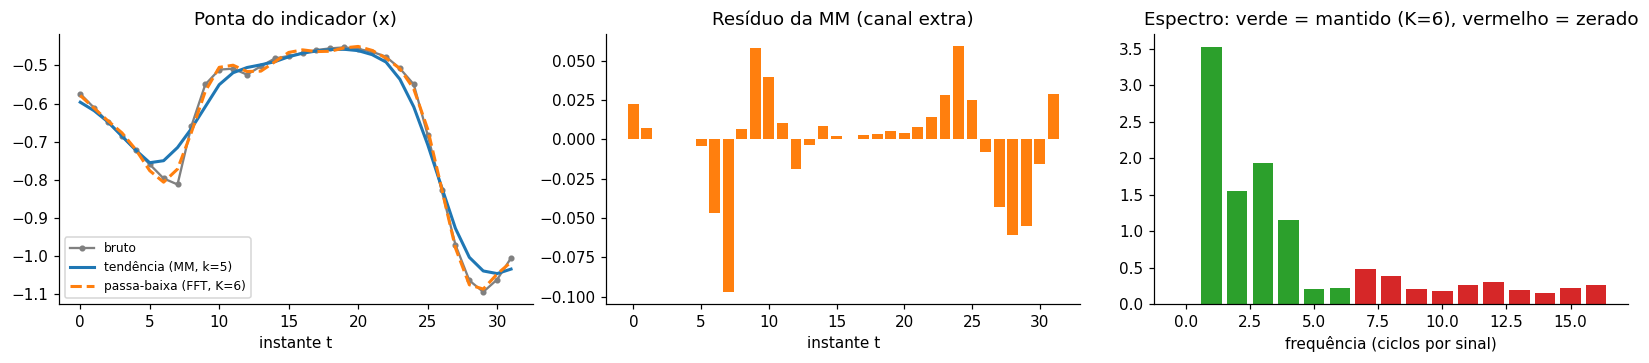

In [7]:
def tec_mm(X, k):
    tend = uniform_filter1d(X, size=k, axis=1, mode="nearest")
    return np.concatenate([tend, X - tend], axis=-1).astype(np.float32)

def tec_fft(X, K_corte):
    t = np.linspace(0, 1, X.shape[1])[None, :, None]
    reta = X[:, :1] + (X[:, -1:] - X[:, :1]) * t           # reta entre o primeiro e o último instante
    espectro = np.fft.rfft(X - reta, axis=1)
    espectro[:, K_corte + 1:] = 0
    return (np.fft.irfft(espectro, n=X.shape[1], axis=1) + reta).astype(np.float32)

def aplicar(tecnica, X, k=None, K_corte=None):
    if tecnica == "bruto":
        return X.astype(np.float32)
    if tecnica == "MM":
        return tec_mm(X, k)
    if tecnica == "FFT":
        return tec_fft(X, K_corte)
    return tec_mm(tec_fft(X, K_corte), k)                    # "Ambas"

# ilustração num canal da ponta do indicador
i = np.where((y == list(classes).index("cinco")) & d["mask"][:, :, 1].all(1))[0][0]
s = X[i:i + 1, :, CI["dom8_x"]][..., None]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
axs[0].plot(s[0, :, 0], "o-", ms=3, color="gray", label="bruto")
axs[0].plot(tec_mm(s, 5)[0, :, 0], lw=2, label="tendência (MM, k=5)")
axs[0].plot(tec_fft(s, 6)[0, :, 0], lw=2, ls="--", label="passa-baixa (FFT, K=6)")
axs[0].legend(fontsize=8); axs[0].set_title("Ponta do indicador (x)"); axs[0].set_xlabel("instante t")
axs[1].bar(range(T), tec_mm(s, 5)[0, :, 1], color="tab:orange"); axs[1].set_title("Resíduo da MM (canal extra)"); axs[1].set_xlabel("instante t")
esp = np.abs(np.fft.rfft(s[0, :, 0] - s[0, :, 0].mean()))
axs[2].bar(range(len(esp)), esp, color=["tab:green" if f <= 6 else "tab:red" for f in range(len(esp))])
axs[2].set_title("Espectro: verde = mantido (K=6), vermelho = zerado"); axs[2].set_xlabel("frequência (ciclos por sinal)")
plt.tight_layout(); salvar_fig("ilustracao_tecnicas"); plt.show()

## 3. Os modelos

As mesmas arquiteturas e o mesmo treino do notebook 03 (para a CNN-1D, a GRU e a híbrida) e do notebook 02 (para o RF: 500 árvores, $\sqrt{p}$ atributos por divisão). A única diferença é o número de canais de entrada (321 ou 642).

In [8]:
def entrada(F):
    x_in = keras.Input(shape=(None, F))
    return x_in, layers.GaussianNoise(0.1)(x_in)

def saida(x_in, h, nome):
    return keras.Model(x_in, layers.Dense(K, activation="softmax")(layers.Dropout(0.3)(h)), name=nome)

def cnn1d(F):
    x_in, h = entrada(F)
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(filtros, k, padding="same")(h)))
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "CNN-1D")

def gru(F):
    x_in, h = entrada(F)
    h = layers.GRU(128, return_sequences=True)(h)
    return saida(x_in, layers.GRU(128)(h), "GRU")

def hibrida(F):
    x_in, h = entrada(F)
    h = layers.BatchNormalization()(layers.Conv1D(128, 5, padding="same", activation="relu")(h))
    h = layers.MaxPooling1D(2)(h)
    h = layers.Conv1D(128, 3, padding="same", activation="relu")(h)
    return saida(x_in, layers.GRU(128)(h), "Conv1D_GRU")

REDES = {"CNN-1D": cnn1d, "GRU": gru, "Conv1D+GRU": hibrida}

def treinar_avaliar(nome, Z, tr, va, te, semente):
    # devolve (previsões de validação, previsões de teste, épocas)
    if nome == "Random Forest":
        m = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=semente)
        M = Z.reshape(len(Z), -1)
        m.fit(M[tr], y[tr])
        return m.predict(M[va]), m.predict(M[te]), 0
    keras.utils.set_random_seed(semente)
    m = REDES[nome](Z.shape[-1])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
    h = m.fit(Z[tr], y[tr], validation_data=(Z[va], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE, callbacks=cb, verbose=0)
    pv, pt = m.predict(Z[va], verbose=0).argmax(1), m.predict(Z[te], verbose=0).argmax(1)
    keras.backend.clear_session()
    return pv, pt, int(np.argmin(h.history["val_loss"])) + 1

## 4. Escolha dos parâmetros das técnicas (só na validação)

A janela $k$ da média móvel e o corte $K$ da FFT são hiperparâmetros. Para não escolhê-los olhando o teste, testamos alguns valores com a **CNN-1D** (o melhor modelo do notebook 03), semente 0, nas 4 rodadas, e escolhemos pelo **F1 macro médio na validação**:

- $k \in \{3, 5, 7\}$ instantes (de ~0,3 s a ~0,7 s do trecho ativo);
- $K \in \{4, 6, 8, 10\}$ ciclos por sinal (de 25% a 60% da frequência de Nyquist, que é 16).

Os valores escolhidos valem para todos os modelos.

In [9]:
ARQ_PAR = RES / "04_escolha_parametros.csv"
par = pd.read_csv(ARQ_PAR) if ARQ_PAR.exists() else pd.DataFrame(columns=["tecnica", "valor", "rodada"])
ja = set(zip(par.tecnica, par.valor, par.rodada))
CANDIDATOS = [("MM", k) for k in [3, 5, 7]] + [("FFT", Kc) for Kc in [4, 6, 8, 10]]
for k_r in RODADAS:
    tr, va, te = particao(k_r)
    for tecnica, valor in CANDIDATOS:
        if (tecnica, valor, k_r) in ja:
            continue
        Xt = tec_mm(X, valor) if tecnica == "MM" else tec_fft(X, valor)
        pv, _, ep = treinar_avaliar("CNN-1D", padronizar(Xt, tr), tr, va, te, 0)
        par = pd.concat([par, pd.DataFrame([dict(tecnica=tecnica, valor=valor, rodada=k_r,
                                                 f1_validacao=f1_score(y[va], pv, average="macro"))])], ignore_index=True)
        par.to_csv(ARQ_PAR, index=False)
        print(f"rodada {k_r} | {tecnica} {valor:2d} | F1 validação {par.f1_validacao.iloc[-1]:.3f}", flush=True)

tab_par = par.pivot_table(index=["tecnica", "valor"], columns="rodada", values="f1_validacao")
tab_par["média"] = tab_par.mean(1)
display((100 * tab_par).round(1))
K_MM = int(tab_par.loc["MM", "média"].idxmax())
K_FFT = int(tab_par.loc["FFT", "média"].idxmax())
print(f"escolhidos na validação: janela da média móvel k = {K_MM} | corte da FFT K = {K_FFT}")

rodada 0 | MM  3 | F1 validação 0.975
rodada 0 | MM  5 | F1 validação 0.961
rodada 0 | MM  7 | F1 validação 0.945
rodada 0 | FFT  4 | F1 validação 0.958
rodada 0 | FFT  6 | F1 validação 0.948
rodada 0 | FFT  8 | F1 validação 0.975
rodada 0 | FFT 10 | F1 validação 0.970
rodada 1 | MM  3 | F1 validação 0.963
rodada 1 | MM  5 | F1 validação 0.962
rodada 1 | MM  7 | F1 validação 0.953
rodada 1 | FFT  4 | F1 validação 0.949
rodada 1 | FFT  6 | F1 validação 0.987
rodada 1 | FFT  8 | F1 validação 0.957
rodada 1 | FFT 10 | F1 validação 0.955
rodada 2 | MM  3 | F1 validação 0.909
rodada 2 | MM  5 | F1 validação 0.920
rodada 2 | MM  7 | F1 validação 0.930
rodada 2 | FFT  4 | F1 validação 0.928
rodada 2 | FFT  6 | F1 validação 0.904
rodada 2 | FFT  8 | F1 validação 0.914
rodada 2 | FFT 10 | F1 validação 0.927
rodada 3 | MM  3 | F1 validação 0.909
rodada 3 | MM  5 | F1 validação 0.904
rodada 3 | MM  7 | F1 validação 0.910
rodada 3 | FFT  4 | F1 validação 0.914
rodada 3 | FFT  6 | F1 validação 0.90

rodada            0     1     2     3  média
tecnica valor                               
FFT     4      95.8  94.9  92.8  91.4   93.8
        6      94.8  98.7  90.4  90.2   93.5
        8      97.5  95.7  91.4  91.4   94.0
        10     97.0  95.5  92.7  91.4   94.2
MM      3      97.5  96.3  90.9  90.9   93.9
        5      96.1  96.2  92.0  90.4   93.7
        7      94.5  95.3  93.0  91.0   93.4

escolhidos na validação: janela da média móvel k = 3 | corte da FFT K = 10


## 5. Ablação

4 versões dos dados × 4 modelos × 4 rodadas × 3 sementes = 192 treinos. Cada treino é gravado em `resultados/04_ablacao_por_rodada.csv` assim que termina.

In [10]:
TECNICAS = ["bruto", "MM", "FFT", "Ambas"]
MODELOS = ["Random Forest", "CNN-1D", "GRU", "Conv1D+GRU"]
ARQ = RES / "04_ablacao_por_rodada.csv"
abl = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame(columns=["tecnica", "modelo", "rodada", "semente"])
ARQ_PRED = RES / "04_previsoes_semente0.csv"                       # previsões de teste da semente 0, para a seção 6.2
prev = pd.read_csv(ARQ_PRED) if ARQ_PRED.exists() else pd.DataFrame({"y": y, "sinalizante": sinalizante})
ja = set(zip(abl.tecnica, abl.modelo, abl.rodada, abl.semente))
VERSOES = {t: aplicar(t, X, K_MM, K_FFT) for t in TECNICAS}
print({t: v.shape for t, v in VERSOES.items()})

for k_r in RODADAS:
    tr, va, te = particao(k_r)
    for tecnica in TECNICAS:
        Z = padronizar(VERSOES[tecnica], tr)
        for modelo in MODELOS:
            for s in SEMENTES:
                if (tecnica, modelo, k_r, s) in ja:
                    continue
                t_ini = time.time()
                _, pt, ep = treinar_avaliar(modelo, Z, tr, va, te, s)
                linha = dict(tecnica=tecnica, modelo=modelo, rodada=k_r, semente=s, melhor_epoca=ep,
                             tempo_s=time.time() - t_ini, **metricas(y[te], pt))
                abl = pd.concat([abl, pd.DataFrame([linha])], ignore_index=True)
                abl.to_csv(ARQ, index=False)
                if s == 0:
                    col = f"{modelo}|{tecnica}"
                    if col not in prev:
                        prev[col] = -1
                    prev.loc[te, col] = pt
                    prev.to_csv(ARQ_PRED, index=False)
                print(f"rodada {k_r} | {tecnica:5s} | {modelo:13s} | semente {s} | F1 teste {linha['f1_macro']:.3f} "
                      f"| {linha['tempo_s']:.0f}s", flush=True)
print("treinos concluídos:", len(abl))

{'bruto': (1158, 32, 321), 'MM': (1158, 32, 642), 'FFT': (1158, 32, 321), 'Ambas': (1158, 32, 642)}
rodada 0 | bruto | Random Forest | semente 0 | F1 teste 0.898 | 20s
rodada 0 | bruto | Random Forest | semente 1 | F1 teste 0.910 | 18s
rodada 0 | bruto | Random Forest | semente 2 | F1 teste 0.911 | 18s
rodada 0 | bruto | CNN-1D        | semente 0 | F1 teste 0.906 | 29s
rodada 0 | bruto | CNN-1D        | semente 1 | F1 teste 0.916 | 24s
rodada 0 | bruto | CNN-1D        | semente 2 | F1 teste 0.882 | 30s
rodada 0 | bruto | GRU           | semente 0 | F1 teste 0.823 | 33s
rodada 0 | bruto | GRU           | semente 1 | F1 teste 0.845 | 39s
rodada 0 | bruto | GRU           | semente 2 | F1 teste 0.847 | 22s
rodada 0 | bruto | Conv1D+GRU    | semente 0 | F1 teste 0.886 | 35s
rodada 0 | bruto | Conv1D+GRU    | semente 1 | F1 teste 0.909 | 34s
rodada 0 | bruto | Conv1D+GRU    | semente 2 | F1 teste 0.911 | 61s
rodada 0 | MM    | Random Forest | semente 0 | F1 teste 0.915 | 26s
rodada 0 | MM   

## 6. Resultados

### 6.1 Tabela da ablação

F1 macro no teste (média ± desvio sobre rodadas × sementes) e o **ganho em relação ao bruto** (Δ, em pontos percentuais). O Δ é calculado **par a par** (mesma rodada e mesma semente) e testado com o **teste de Wilcoxon pareado** (12 pares por célula): $p < 0{,}05$ indica que o ganho ou a perda é consistente, e não fruto da variação entre rodadas.

In [11]:
abl = pd.read_csv(ARQ)
base = abl[abl.tecnica == "bruto"].set_index(["modelo", "rodada", "semente"]).f1_macro
linhas = []
for modelo in MODELOS:
    for tecnica in TECNICAS:
        v = abl[(abl.modelo == modelo) & (abl.tecnica == tecnica)].set_index(["modelo", "rodada", "semente"]).f1_macro
        linha = {"modelo": modelo, "técnica": tecnica, "F1 macro (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}"}
        if tecnica != "bruto":
            delta = (v - base.reindex(v.index)).dropna()
            p = wilcoxon(delta).pvalue if len(delta) >= 6 and np.any(delta != 0) else np.nan
            linha.update({"Δ vs bruto (p.p.)": f"{100 * delta.mean():+.1f}", "p (Wilcoxon)": f"{p:.3f}",
                          "pares que melhoraram": f"{int((delta > 0).sum())}/{len(delta)}"})
        linhas.append(linha)
tab_abl = pd.DataFrame(linhas).set_index(["modelo", "técnica"]).fillna("—")
display(tab_abl)
tab_abl.to_csv(RES / "04_tabela_ablacao.csv")

F1 macro (%) Δ vs bruto (p.p.) p (Wilcoxon)  \
modelo        técnica                                               
Random Forest bruto     89.0 ± 3.6                 —            —   
              MM        89.4 ± 4.0              +0.4        0.151   
              FFT       88.9 ± 3.9              -0.1        0.850   
              Ambas     89.1 ± 4.3              +0.1        0.733   
CNN-1D        bruto     91.2 ± 2.3                 —            —   
              MM        91.0 ± 2.7              -0.2        0.910   
              FFT       90.4 ± 3.0              -0.8        0.301   
              Ambas     91.3 ± 2.3              +0.2        0.569   
GRU           bruto     83.8 ± 2.2                 —            —   
              MM        78.3 ± 4.6              -5.5        0.001   
              FFT       83.3 ± 1.8              -0.5        0.301   
              Ambas     76.7 ± 3.8              -7.1        0.000   
Conv1D+GRU    bruto     88.4 ± 2.4                 —            —   
              MM        87.7 ± 2.0              -0.6        0.301   
              FFT       88.3 ± 2.6              -0.1        0.733   
              Ambas     86.4 ± 2.1              -1.9        0.064   

                      pares que melhoraram  
modelo        técnica                       
Random Forest bruto                      —  
              MM                      9/12  
              FFT                     7/12  
              Ambas                   5/12  
CNN-1D        bruto                      —  
              MM                      6/12  
              FFT                     4/12  
              Ambas                   7/12  
GRU           bruto                      —  
              MM                      1/12  
              FFT                     5/12  
              Ambas                   0/12  
Conv1D+GRU    bruto                      —  
              MM                      5/12  
              FFT                     5/12  
              Ambas                   3/12

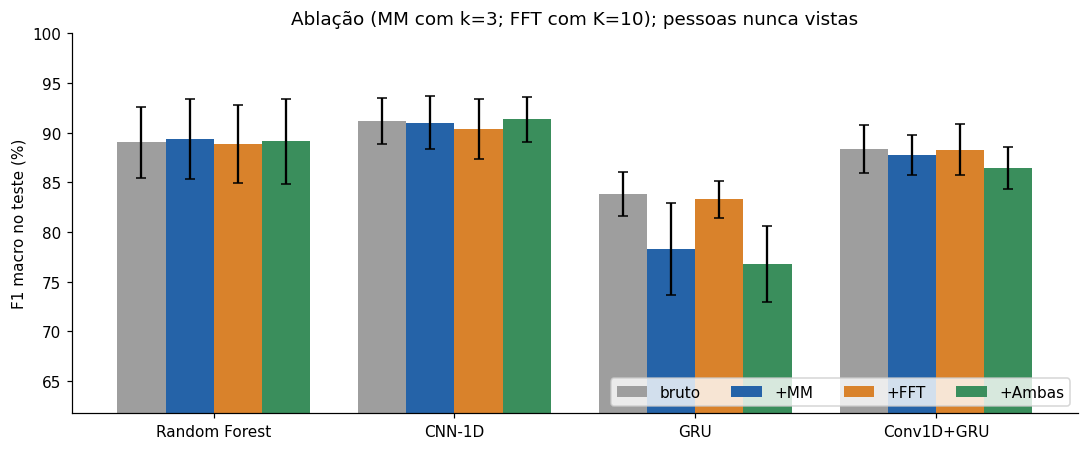

In [12]:
media = abl.groupby(["modelo", "tecnica"]).f1_macro.mean().unstack()[TECNICAS].reindex(MODELOS)
desvio = abl.groupby(["modelo", "tecnica"]).f1_macro.std().unstack()[TECNICAS].reindex(MODELOS)
fig, ax = plt.subplots(figsize=(10, 4.2))
larg = 0.2
cores = {"bruto": "#9e9e9e", "MM": "#2563A8", "FFT": "#D9822B", "Ambas": "#3A8E5C"}
for j, t in enumerate(TECNICAS):
    ax.bar(np.arange(len(MODELOS)) + (j - 1.5) * larg, 100 * media[t], larg, yerr=100 * desvio[t],
           capsize=3, color=cores[t], label=t if t == "bruto" else f"+{t}")
ax.set_xticks(range(len(MODELOS)), MODELOS); ax.set_ylabel("F1 macro no teste (%)")
ax.set_ylim(max(0, 100 * media.values.min() - 15), 100)
ax.set_title(f"Ablação (MM com k={K_MM}; FFT com K={K_FFT}); pessoas nunca vistas")
ax.legend(ncol=4, loc="lower right"); plt.tight_layout(); salvar_fig("ablacao_barras"); plt.show()

### 6.2 Onde a técnica ajudou ou atrapalhou

Comparação na **semente 0** (as 4 rodadas juntas: cada vídeo é teste uma vez), técnica contra bruto:

- **por sinalizante:** ganho de acurácia de cada pessoa, ao lado da fração de instantes em que o MediaPipe **perdeu a mão dominante** naquela pessoa. Se a técnica ajuda mais onde há mais falhas, o mecanismo é a remoção dos "degraus" criados pelas falhas;
- **por palavra:** ganho de F1. Se a FFT atrapalha palavras com movimento rápido dos dedos, o corte removeu informação útil, e não só ruído.

In [13]:
prev = pd.read_csv(ARQ_PRED)
dom_cols = [CI[f"dom{j}_x"] for j in range(21)]
falha_mao = pd.Series([(X[sinalizante == s_][:, :, dom_cols] == 0).all(-1).mean() for s_ in range(1, 13)],
                      index=[f"S{s_:02d}" for s_ in range(1, 13)])

def acc_por_pessoa(col):
    # acurácia por sinalizante; vazio (NaN) se aquela pessoa ainda não foi testada (execução interrompida)
    out = []
    for s_ in range(1, 13):
        sel = (prev.sinalizante == s_) & (prev[col] >= 0)
        out.append(accuracy_score(prev.y[sel], prev[col][sel]) if sel.any() else np.nan)
    return pd.Series(out, index=falha_mao.index)

for modelo in ["Random Forest", "CNN-1D"]:
    if f"{modelo}|bruto" not in prev:
        continue
    tab_p = pd.DataFrame({"mão ausente (%)": 100 * falha_mao, "acurácia bruto (%)": 100 * acc_por_pessoa(f"{modelo}|bruto")})
    for t in TECNICAS[1:]:
        if f"{modelo}|{t}" in prev:
            tab_p[f"Δ {t}"] = 100 * (acc_por_pessoa(f"{modelo}|{t}") - acc_por_pessoa(f"{modelo}|bruto"))
    print(f"\n{modelo}: correlação (Spearman) entre mão ausente e ganho:",
          {t: round(float(tab_p["mão ausente (%)"].corr(tab_p[f"Δ {t}"], method="spearman")), 2) for t in TECNICAS[1:] if f"Δ {t}" in tab_p})
    display(tab_p.round(1))

cols_cnn = [f"CNN-1D|{t}" for t in TECNICAS if f"CNN-1D|{t}" in prev]
ok = (prev[cols_cnn] >= 0).all(1)
f1_pal = pd.DataFrame({c.split("|")[1]: f1_score(prev.y[ok], prev[c][ok], average=None, labels=range(K)) for c in cols_cnn},
                      index=classes)
for t in TECNICAS[1:]:
    if t in f1_pal:
        f1_pal[f"Δ {t}"] = f1_pal[t] - f1_pal["bruto"]
print("\nCNN-1D: F1 por palavra (%), ordenado pelo ganho da FFT")
display((100 * f1_pal.sort_values("Δ FFT" if "Δ FFT" in f1_pal else "bruto")).round(0).astype(int))


Random Forest: correlação (Spearman) entre mão ausente e ganho: {'MM': 0.29, 'FFT': -0.03, 'Ambas': -0.14}


,mão ausente (%),acurácia bruto (%),Δ MM,Δ FFT,Δ Ambas
S01,24.0,89.0,1.0,1.0,1.0
S02,21.6,98.0,0.0,-1.0,-1.0
S03,0.0,89.4,-1.2,0.0,0.0
S04,12.2,88.4,1.1,2.1,2.1
S05,23.9,91.0,2.0,0.0,0.0
S06,1.7,87.0,2.0,2.0,1.0
S07,6.3,80.6,-1.9,-1.9,-1.0
S08,0.6,95.0,1.0,0.0,2.0
S09,15.2,97.3,0.0,0.0,-1.3
S10,24.1,87.0,0.0,-2.0,-1.0



CNN-1D: correlação (Spearman) entre mão ausente e ganho: {'MM': 0.72, 'FFT': 0.55, 'Ambas': 0.51}


,mão ausente (%),acurácia bruto (%),Δ MM,Δ FFT,Δ Ambas
S01,24.0,94.0,0.0,1.0,1.0
S02,21.6,98.0,0.0,-1.0,1.0
S03,0.0,97.6,-2.4,-5.9,-4.7
S04,12.2,83.2,-3.2,-4.2,2.1
S05,23.9,94.0,0.0,0.0,-1.0
S06,1.7,98.0,-1.0,1.0,0.0
S07,6.3,88.3,-2.9,-1.0,-1.0
S08,0.6,98.0,-9.0,-1.0,0.0
S09,15.2,90.7,1.3,-2.7,4.0
S10,24.1,87.0,3.0,1.0,1.0



CNN-1D: F1 por palavra (%), ordenado pelo ganho da FFT


,bruto,MM,FFT,Ambas,Δ MM,Δ FFT,Δ Ambas
aluno,91,85,85,88,-6,-6,-3
filho,75,72,71,75,-3,-5,-1
vontade,96,97,92,100,1,-4,4
cinco,91,88,88,89,-4,-3,-2
barulho,89,85,87,86,-5,-2,-3
conhecer,95,89,93,96,-5,-2,2
banheiro,99,96,97,99,-3,-2,0
vacina,97,94,95,95,-2,-2,-2
amarelo,91,83,90,92,-8,-1,1
aproveitar,95,95,94,96,0,-1,1


In [14]:
# Baixa resultados e figuras (plano B do Colab: /content é apagado quando o Colab desconecta)
if "google.colab" in sys.modules and not str(BASE).startswith("/content/drive"):
    import shutil
    from google.colab import files
    shutil.make_archive("/content/resultados_04", "zip", "/content/trabalho_series_temporais")
    files.download("/content/resultados_04.zip")
else:
    print("resultados gravados em", RES)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Síntese

**Resultado principal: nenhuma das técnicas melhorou de forma consistente nenhum modelo.** Nas árvores e nas redes convolucionais o efeito é nulo; na GRU, a decomposição piora.

| Modelo | bruto | +MM (k=3) | +FFT (K=10) | Ambas |
|---|---|---|---|---|
| Random Forest | 89,0 | 89,4 (+0,4; p=0,15) | 88,9 (−0,1) | 89,1 (+0,1) |
| CNN-1D | 91,2 | 91,0 (−0,2) | 90,4 (−0,8; p=0,30) | 91,3 (+0,2) |
| GRU | 83,8 | **78,3 (−5,5; p=0,001)** | 83,3 (−0,5) | **76,7 (−7,1; p<0,001)** |
| Conv1D+GRU | 88,4 | 87,7 (−0,6) | 88,3 (−0,1) | 86,4 (−1,9; p=0,06) |

*F1 macro (%), média de 4 rodadas × 3 sementes; entre parênteses, Δ pareado em relação ao bruto e p do teste de Wilcoxon.*

**Referência de ruído:** a coluna "bruto" repete exatamente os treinos do notebook 03 (mesmas sementes) e mesmo assim varia até 0,6 ponto, por causa do não determinismo da GPU. Diferenças menores que ~1 ponto não devem ser interpretadas.

**1. A própria escolha dos parâmetros já indicava o resultado.** Na validação, todos os valores ficaram entre 93,4% e 94,2% de F1, e os escolhidos foram os que **menos alteram** o sinal: a menor janela de média móvel (k = 3) e o corte mais alto da FFT (K = 10 de 16). Ou seja, quanto menos se filtra, melhor, ou no máximo indiferente.

**2. Por que não ajudou nas árvores e na CNN-1D.** As convoluções da CNN já são filtros aprendidos: a primeira camada pode aprender, sozinha, uma média móvel ou um passa-baixa se isso for útil, e a filtragem explícita fica redundante. No Random Forest sobre *lags*, cada divisão escolhe as colunas mais informativas; os canais de resíduo raramente são escolhidos e quase não mudam o modelo (9 de 12 pares melhoraram com a MM, mas só +0,4 ponto, sem significância).

**3. Por que a decomposição piorou a GRU.** O que prejudica não é a suavização em si: a FFT, que suaviza sem acrescentar canais, é neutra na GRU (−0,5, n.s.). O dano vem de **dobrar a entrada para 642 canais**, metade deles de resíduo, que é quase só ruído. A GRU recebe esse ruído a cada instante, no próprio estado recorrente; com ~670 vídeos de treino, ela se ajusta a ele (−5,5 a −7,1 pontos, piorando em 11 ou 12 dos 12 pares). A CNN e a híbrida resumem os canais com a convolução antes de qualquer recorrência e sofrem bem menos.

**4. O mecanismo esperado existe, mas se compensa.** Na CNN-1D, o ganho por sinalizante se correlaciona com a fração de instantes em que o MediaPipe perdeu a mão dominante (Spearman ρ = 0,72, p = 0,009 para a MM; ρ = 0,55, p = 0,06 para a FFT). As técnicas ajudam as pessoas com **muitas falhas de detecção** (S09, S10: 15–24% de mão ausente), porque suavizam os "degraus" criados pelas falhas, e atrapalham as pessoas com **detecção limpa** (S03, S08, S12: menos de 1%), em que só removem detalhe útil. No conjunto, os efeitos se anulam.

**5. O que a FFT corta não é só ruído.** As palavras que mais perdem com o passa-baixa são *aluno*, *filho*, *vontade* e *cinco* (−3 a −6 pontos), sinais com mudanças rápidas de configuração dos dedos. Mesmo com o corte em 10 de 16 ciclos, parte do conteúdo de alta frequência é movimento real da mão.

**6. Custo × benefício.** A MM dobra o número de canais e aumenta o tempo de treino do RF em 40–50%, sem ganho. Para este problema, a recomendação é **usar o sinal bruto**: o gargalo não é o ruído do MediaPipe, e sim a variação entre sinalizantes (notebooks 02 e 03). Um pré-processamento que valeria a pena testar, em vez de filtrar, é **mascarar as falhas** (preencher a mão ausente por interpolação ou indicar a ausência com a máscara), já que é nos sinalizantes com mais falhas que está o ganho potencial.
